# Multiparity calibration, Floquet populations, then AGP

Follow the same direct runner / experiment-object pattern as Jonginn's
qsim_experiments_highkerr_untracked_refactored.ipynb (Fock calibration and
multiparity population cells). Run the measurement cells you want to acquire.
Every execute call submits to the worker and returns the ordinary experiment.
Plot those objects directly; no folder search or automatic merge of old runs.

ro_stor=0 reads manipulate. ro_stor=2 reads physical Storage 2, and so on.
postpulse=True uses the existing Qsim storage swap before multiparity readout.
Only multimode Fock loading is supplied by FockPopulationProgram.

In [1]:
%load_ext autoreload
%autoreload 2

from copy import deepcopy
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

## 1. Station and worker

User and configuration versions are the same as the saved production notebook.
No measurement is submitted by constructing the runner below.

In [47]:
from slab import AttrDict
from experiments import CharacterizationRunner, MultimodeStation
from job_server import JobClient

from experiments.qsim.fock_population import FockPopulationProgram
from experiments.qsim.qsim_base import QsimExperiment
from experiments.qsim.notebook_helpers.defaults import (
    ACTIVE_RESET_DEFAULTS, FLOQUET_DEFAULTS,
)

user = "jonginn"
config_dict = {'hardware_config': 'CFG-HW-20261019-00058',
 'multiphoton_config': 'CFG-MP-20260121-00001',
 'man1_storage_swap': 'CFG-M1-20261019-00001',
 'floquet_storage_swap': 'CFG-FL-20261017-00034'}


client = JobClient()
health = client.health_check()
print(f"Server status: {health['status']}")
client.print_queue()

station = MultimodeStation(
    user=user,
    experiment_name="agp_k44_first_scan",
    project="AGP",
    log_measurements=False,
    hardware_config=config_dict["hardware_config"],
    multiphoton_config=config_dict["multiphoton_config"],
    storage_man_file=config_dict["man1_storage_swap"],
    floquet_file=config_dict["floquet_storage_swap"],
)

Server status: healthy

=== Job Queue ===

No job currently running

Pending: 0 jobs

[STATION] Using hardware_config version: CFG-HW-20261019-00058
[STATION] Using multiphoton_config version: CFG-MP-20260121-00001
[STATION] Using man1_storage_swap version: CFG-M1-20261019-00001
[STATION] Using floquet_storage_swap version: CFG-FL-20261017-00034
[STATION] Lab-notebook vault: G:\Shared drives\SLab\Multimode
Data, plots, logs will be stored in: C:\experiments\agp_k44_first_scan
Hardware configs will be read from C:\python\multimode_expts\configs\versions\hardware_config\CFG-HW-20261019-00058.yml
dict_keys(['Pyro.NameServer', 'Qick101'])
QICK running on ZCU216, software version 0.2.291

Firmware configuration (built Tue Oct 15 12:06:51 2024):

	Global clocks (MHz): tProcessor 430.080, RF reference 245.760

	7 signal generator channels:
	0:	axis_signal_gen_v6 - envelope memory 32768 samples (5.128 us)
		fs=6389.760 MHz, fabric=399.360 MHz, 32-bit DDS, range=6389.760 MHz
		DAC tile 2, blk 0

In [48]:
# Common pulse/reset settings. Acquisition settings are written at each call.
population_defaults = AttrDict(dict(
    expts=1, reps=1, rounds=1, qubits=[0], f0g1_cavity=1,
    normalize=False, active_reset=True, man_reset=True,
    storage_reset=[4, 5, 6, 7], pre_relax_delay=100, relax_delay=200,
    prepulse=False, postpulse=True, init_fock=False, init_stor=0,
    readout="multiparity", parity_fast=False,
    cond_sec_phase=-90, phase_second_pulse=180,
    occupations=[3, 0, 0, 0, 0], swap_stors=[4, 5, 6, 7],
    use_multiphoton_swap=False, storage_pulse_wait_us=0.2, ro_stor=0,
    update_phases=True, detunings=[0.0, 0.0, 0.0, 0.0],
    floquet_cycles=[0], swept_params=["floquet_cycle"],
))
population_defaults.update(ACTIVE_RESET_DEFAULTS)
population_defaults.update(FLOQUET_DEFAULTS)


def population_preprocessor(station, defaults, **overrides):
    settings = deepcopy(defaults)
    settings.update(overrides)
    return settings


population_runner = CharacterizationRunner(
    station=station,
    ExptClass=QsimExperiment,
    ExptProgram=FockPopulationProgram,
    default_expt_cfg=population_defaults,
    preprocessor=population_preprocessor,
    job_client=client,
    use_queue=True,
    show=False,
)

## 2. Fock 0, 1, 2, 3 readout calibration

Each call returns an experiment object. readout_expts contains only this run.
Use readout_expts[0].data or readout_expts[0].analyze_multiparity() directly.

In [49]:
readout_expts = []
for number in range(4):
    readout_expt = population_runner.execute(
        use_queue=True,
        reps=6000,
        occupations=[number, 0, 0, 0, 0],
        swap_stors=[4, 5, 6, 7],
        storage_reset=[4, 5, 6, 7],
        ro_stor=0,
        readout="multiparity",
        prepulse=False,
        postpulse=True,
        detunings=[0.0, 0.0, 0.0, 0.0],
        floquet_cycles=[0],
        postprocess=False, show=False, log=False,
    )
    readout_expts.append(readout_expt)
    print(readout_expt.fname)

Job submitted: JOB-20261019-00131 (queue position: 1)

[9.6s] Job JOB-20261019-00131: completed
[WORKER] Loading QsimExperiment from experiments.qsim.qsim_base
[WORKER] Creating experiment instance
[WORKER]   Data file: JOB-20261019-00131_QsimExperiment.h5
[WORKER]   Program: FockPopulationProgram from experiments.qsim.fock_population
[WORKER] Running experiment...
[WORKER] Setting coupler yoko current to 0.25mA according to hardware_cfg yaml...
[WORKER] Done setting coupler current
100%|████████████████████████████████████████████| 1/1 [00:05<00:00,  5.31s/it]
Saving C:\experiments\agp_k44_first_scan\data\JOB-20261019-00131_QsimExperiment.h5
[WORKER] Saving expt object to: C:\experiments\agp_k44_first_scan\expt_objs\JOB-20261019-00131_expt.pkl

Job completed! Data: C:\experiments\agp_k44_first_scan\data\JOB-20261019-00131_QsimExperiment.h5
C:\experiments\agp_k44_first_scan\data\JOB-20261019-00131_QsimExperiment.h5
Job submitted: JOB-20261019-00133 (queue position: 1)

[7.5s] Job JOB-2

C:\experiments\agp_k44_first_scan\data\JOB-20261019-00131_QsimExperiment.h5
C:\experiments\agp_k44_first_scan\data\JOB-20261019-00133_QsimExperiment.h5
C:\experiments\agp_k44_first_scan\data\JOB-20261019-00134_QsimExperiment.h5
C:\experiments\agp_k44_first_scan\data\JOB-20261019-00135_QsimExperiment.h5


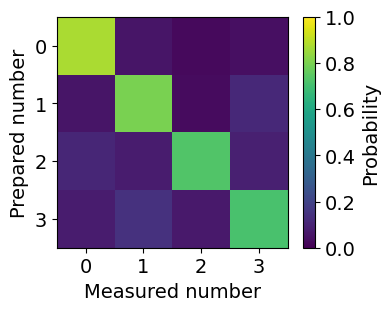

Confusion matrix condition number: 1.6632109215541588


In [50]:
# C[prepared number, measured number]. This is the matrix used below.
readout_confusion = np.zeros((4, 4))
for readout_expt in readout_expts:
    number = readout_expt.cfg.expt.occupations[0]
    multiparity = readout_expt.analyze_multiparity()
    readout_confusion[number] = [multiparity[f"p_mod{n}"][0] for n in range(4)]
    print(readout_expt.fname)

fig, axis = plt.subplots(figsize=(4, 3))
image = axis.imshow(readout_confusion, vmin=0, vmax=1)
axis.set(xlabel="Measured number", ylabel="Prepared number", xticks=range(4), yticks=range(4))
fig.colorbar(image, ax=axis, label="Probability")
plt.show()
print("Confusion matrix condition number:", np.linalg.cond(readout_confusion))

## 3. Floquet population measurement

Set meas_stors here: [0] for man; [0, 2, 3, 4, 5] to measure all five modes.
Each mode uses a fresh preparation and a separate job. No AGP settings enter.
Cycles below are 0, 2, ..., 934; the stop value in range is exclusive.

In [ ]:
swap_stors = [4, 5, 6, 7]
meas_stors = [0] + swap_stors

occupations = [3, 0, 0, 0, 0]
detunings = [0.0, 0.0, 0.0, 0.0]  # MHz; zero disorder
floquet_cycles = list(range(0, 100, 2))

walk_expts = []
for meas_stor in meas_stors:
    walk_expt = population_runner.execute(
        use_queue=True,
        reps=300,
        occupations=occupations,
        swap_stors=swap_stors,
        storage_reset=swap_stors,
        ro_stor=meas_stor,
        readout="multiparity",
        prepulse=False,
        postpulse=True,
        detunings=detunings,
        floquet_cycles=floquet_cycles,
        postprocess=False, show=False, log=False,
    )
    walk_expts.append(walk_expt)
    print(walk_expt.fname)

Job submitted: JOB-20261019-00137 (queue position: 1)

[15.6s] Job JOB-20261019-00137: pending

[126.6s] Job JOB-20261019-00137: running
[WORKER] Loading QsimExperiment from experiments.qsim.qsim_base
[WORKER] Creating experiment instance
[WORKER]   Data file: JOB-20261019-00137_QsimExperiment.h5
[WORKER]   Program: FockPopulationProgram from experiments.qsim.fock_population
[WORKER] Running experiment...
[WORKER] Setting coupler yoko current to 0.25mA according to hardware_cfg yaml...
[WORKER] Done setting coupler current
 88%|████████████████████████████████████▉     | 44/50 [00:19<00:02,  2.24it/s]

In [ ]:
for walk_expt in walk_expts:
    print(walk_expt.fname)

In [ ]:
# This loop plots only the experiment objects in walk_expts.
# Correction is explicit: p_measured = C.T @ p_true. Do not clip negatives.
fig, axes = plt.subplots(2, 1, figsize=(10, 7))
for walk_expt in walk_expts:
    multiparity = walk_expt.analyze_multiparity()
    raw_probability = np.column_stack([multiparity[f"p_mod{n}"] for n in range(4)])
    corrected_probability = np.linalg.solve(readout_confusion.T, raw_probability.T).T
    raw_mean_number = raw_probability @ np.arange(4)
    corrected_mean_number = corrected_probability @ np.arange(4)
    cycles = multiparity["xpts"]

    # image = axes[0].pcolormesh(cycles, np.arange(4), corrected_probability.T, shading="nearest")
    # axes[0].set(xlabel="Floquet cycles", ylabel="Measured number modulo 4")
    # fig.colorbar(image, ax=axes[0], label="Corrected probability")
    axes[0].plot(cycles, raw_mean_number, label=f"Raw, Mode {walk_expt.cfg.expt.ro_stor}")
    axes[1].plot(cycles, corrected_mean_number, label=f"Confusion corrected, Mode {walk_expt.cfg.expt.ro_stor}")
    axes[0].set(xlabel="Floquet cycles", ylabel="Mean number")
    axes[1].set(xlabel="Floquet cycles", ylabel="Mean number")
    axes[0].legend()
    axes[1].legend()
    label = "man" if walk_expt.cfg.expt.ro_stor == 0 else f"Storage {walk_expt.cfg.expt.ro_stor}"
# fig.suptitle(f"Readout: {label}")
fig.tight_layout()
plt.show()

In [ ]:
import json
import h5py
import numpy as np
from IPython.display import display
from fitting.qsim.mbr_hamiltonian import fixed_n_hamiltonian

KERR_KHZ = -27.0  # Set K / (2*pi), including its sign.

theory_axis = axes[1]

# Remove only previously added theory curves when rerunning this cell.
for line in list(theory_axis.lines):
    if line.get_label().startswith("Theory,"):
        line.remove()
measured_colors = {line.get_label(): line.get_color() for line in theory_axis.lines}

for plot_index, walk_expt in enumerate(walk_expts):
    settings = walk_expt.cfg.expt
    storages = list(settings.swap_stors)
    initial_occupation = tuple(settings.occupations)
    photon_number = sum(initial_occupation)
    mode_count = 1 + len(storages)
    readout_storage = settings.ro_stor
    readout_index = ([0] + storages).index(readout_storage)

    # Read only this experiment's saved timing and couplings; no live hardware.
    with h5py.File(walk_expt.fname, "r") as data_file:
        timing = json.loads(data_file.attrs["derived_params"])
    cycle_us = float(timing["floquet_cycle_us"])
    couplings_mhz = np.array([timing["couplings_MHz"][s - 1] for s in storages])
    if settings.get("zero_floquet_gain", False):
        couplings_mhz[:] = 0.0
    detunings_mhz = settings.get("detunings")
    if detunings_mhz is None or detunings_mhz is False or len(detunings_mhz) == 0:
        detunings_mhz = np.zeros(len(storages))

    # H/h in MHz: K*n_man*(n_man-1)/2 - sum(delta_s*n_s) + hopping.
    model = fixed_n_hamiltonian(
        photon_number=photon_number,
        mode_count=mode_count,
        detunings=detunings_mhz,
        couplings_MHz=couplings_mhz,
        physical_kerr_MHz=KERR_KHZ / 1000,
    )
    cycles = np.asarray(walk_expt.analyze_multiparity()["xpts"], dtype=float)
    theory_cycles = np.linspace(cycles.min(), cycles.max(), max(1000, len(cycles)))
    time_us = theory_cycles * cycle_us

    initial_index = model.fock_index[initial_occupation]
    eigenstate_amplitudes = model.states[initial_index, :].conj()
    phases = np.exp(-2j * np.pi * model.energies_MHz[:, None] * time_us[None, :])
    state = model.states @ (eigenstate_amplitudes[:, None] * phases)
    probability = np.abs(state) ** 2
    basis = np.asarray(model.fock_basis)
    theory_mean_number = basis[:, readout_index] @ probability
    decay = np.exp
    measured_label = f"Confusion corrected, Mode {readout_storage}"
    color = measured_colors.get(measured_label, f"C{plot_index % 10}")
    theory_axis.plot(
        theory_cycles, theory_mean_number, color=color, alpha=0.45, linewidth=3,
        # label=f"Theory, Mode {readout_storage}",
    )
    print(
        f"Mode {readout_storage}: storages={storages}, input={initial_occupation}, "
        f"K={KERR_KHZ:g} kHz, cycle={cycle_us:.6f} us, "
        f"g={np.round(1000 * couplings_mhz, 3)} kHz"
    )

# theory_axis.legend(ncol=2)
theory_axis.figure.tight_layout()
display(theory_axis.figure)

## 4. AGP settings start here

Everything above is ordinary preparation/evolution/multiparity measurement.
The fixed-N basis and probe weights below are needed only for AGP correlations.
They do not select modes or repetitions for calibration or walk measurements.

In [6]:
from fitting.qsim.agp import (
    build_correlation,
    calibrate_readout,
    finite_time_agp,
    fit_correlation_mpm,
    fock_basis,
    load_analysis_h5,
    load_population_job,
    population_moments,
    probe_weights,
    regularized_agp_from_fit,
    save_analysis_h5,
)

STORAGE_MODES = [4, 5, 6, 7]
TOTAL_PHOTONS = 3
MODE_COUNT = 1 + len(STORAGE_MODES)
OCCUPATIONS = fock_basis(TOTAL_PHOTONS, MODE_COUNT)
DIMENSION = len(OCCUPATIONS)
PROBES = [("Kerr", "kerr", 0)]
PROBES += [(f"Storage {storage}", "number", index + 1)
           for index, storage in enumerate(STORAGE_MODES)]

DISORDER_PATTERN = np.array([-0.70675335,  0.19463085, -1.03457499,  1.54669749])
DISORDER_PATTERN = DISORDER_PATTERN - np.mean(DISORDER_PATTERN)
pattern_rms = np.sqrt(np.mean(DISORDER_PATTERN ** 2))
if pattern_rms > 0:
    DISORDER_PATTERN = DISORDER_PATTERN / pattern_rms
# An all-zero pattern is allowed for W=0. Nonzero W needs a nonzero pattern.

print(f"Fixed N = {TOTAL_PHOTONS}, modes = {MODE_COUNT}, dimension = {DIMENSION}")

Fixed N = 3, modes = 5, dimension = 35


## 5. Kerr pilot

For N=3, only the five inputs with at least two man photons have nonzero
weight for V_K = n_man * (n_man - 1) / 2. The trace normalization stays D=35.
These settings are local to the pilot. Its readout is man, ro_stor=0.

In [ ]:
pilot_disorder_khz = 40.0
floquet_cycles = list(range(0, 935, 2))
if pilot_disorder_khz != 0 and not pattern_rms > 0:
    raise ValueError("Nonzero disorder needs a nonconstant DISORDER_PATTERN; use W=0 to turn disorder off.")
detunings = (0.001 * pilot_disorder_khz * DISORDER_PATTERN).tolist()
kerr_weights = probe_weights(OCCUPATIONS, probe="kerr", mode=0)

pilot_expts = []
for occupation, weight in zip(OCCUPATIONS, kerr_weights):
    if weight == 0:
        continue
    pilot_expt = population_runner.execute(
        use_queue=True,
        reps=1000,
        occupations=list(occupation),
        swap_stors=STORAGE_MODES,
        storage_reset=STORAGE_MODES,
        ro_stor=0,
        readout="multiparity",
        prepulse=False,
        postpulse=True,
        detunings=detunings,
        floquet_cycles=floquet_cycles,
        postprocess=False, show=False, log=False,
    )
    pilot_expts.append(pilot_expt)
    print(pilot_expt.fname)

## 6. AGP disorder scan

Choose the measured modes here, independently of the walk cell above.
[0] measures Kerr only. [0, 2, 3, 4, 5] also measures the four storage probes.
scan_expts[W][probe_name] contains the ordinary returned experiment objects.

In [40]:
meas_stors = [7]#[0] + STORAGE_MODES
DISORDER_RMS_KHZ = [0]
floquet_cycles = list(range(0, 400, 1))
if any(value != 0 for value in DISORDER_RMS_KHZ) and not pattern_rms > 0:
    raise ValueError("Nonzero disorder needs a nonconstant DISORDER_PATTERN; use W=0 to turn disorder off.")

scan_expts = {}
for disorder_khz in DISORDER_RMS_KHZ:
    detunings = (0.001 * disorder_khz * DISORDER_PATTERN).tolist()
    scan_expts[disorder_khz] = {}
    for meas_stor in meas_stors:
        mode = 0 if meas_stor == 0 else STORAGE_MODES.index(meas_stor) + 1
        probe = "kerr" if meas_stor == 0 else "number"
        name = "Kerr" if meas_stor == 0 else f"Storage {meas_stor}"
        weights = probe_weights(OCCUPATIONS, probe=probe, mode=mode)
        scan_expts[disorder_khz][name] = []
        for occupation, weight in zip(OCCUPATIONS, weights):
            if weight == 0:
                continue
            scan_expt = population_runner.execute(
                use_queue=True,
                reps=500,
                occupations=list(occupation),
                swap_stors=STORAGE_MODES,
                storage_reset=STORAGE_MODES,
                ro_stor=meas_stor,
                readout="multiparity",
                prepulse=False,
                postpulse=True,
                detunings=detunings,
                floquet_cycles=floquet_cycles,
                postprocess=False, show=False, log=False,
            )
            scan_expts[disorder_khz][name].append(scan_expt)
            print(scan_expt.fname)

Job submitted: JOB-20261019-00023 (queue position: 1)

[10.8s] Job JOB-20261019-00023: running
[WORKER] Loading QsimExperiment from experiments.qsim.qsim_base
[WORKER] Creating experiment instance
[WORKER]   Data file: JOB-20261019-00023_QsimExperiment.h5
[WORKER]   Program: FockPopulationProgram from experiments.qsim.fock_population
[WORKER] Running experiment...
[WORKER] Setting coupler yoko current to 0.25mA according to hardware_cfg yaml...
[WORKER] Done setting coupler current
 99%|███████████████████████████████████████▋| 397/400 [04:19<00:02,  1.48it/s]
[277.0s] Job JOB-20261019-00023: completed
100%|████████████████████████████████████████| 400/400 [04:21<00:00,  1.53it/s]
Saving C:\experiments\agp_k44_first_scan\data\JOB-20261019-00023_QsimExperiment.h5
[WORKER] Saving expt object to: C:\experiments\agp_k44_first_scan\expt_objs\JOB-20261019-00023_expt.pkl

Job completed! Data: C:\experiments\agp_k44_first_scan\data\JOB-20261019-00023_QsimExperiment.h5
C:\experiments\agp_k44_fi

In [41]:
for scan_expt_disorder_strength, scan_expt_sub_dict in scan_expts.items():
    print(scan_expt_disorder_strength)
    for scan_expt_diction, scan_expt_ind_dict in scan_expt_sub_dict.items():
        print(scan_expt_diction)
        for _ in scan_expt_ind_dict:
            print(_.fname)

0
Storage 7
C:\experiments\agp_k44_first_scan\data\JOB-20261019-00023_QsimExperiment.h5
C:\experiments\agp_k44_first_scan\data\JOB-20261019-00024_QsimExperiment.h5
C:\experiments\agp_k44_first_scan\data\JOB-20261019-00025_QsimExperiment.h5
C:\experiments\agp_k44_first_scan\data\JOB-20261019-00026_QsimExperiment.h5
C:\experiments\agp_k44_first_scan\data\JOB-20261019-00027_QsimExperiment.h5
C:\experiments\agp_k44_first_scan\data\JOB-20261019-00028_QsimExperiment.h5
C:\experiments\agp_k44_first_scan\data\JOB-20261019-00029_QsimExperiment.h5
C:\experiments\agp_k44_first_scan\data\JOB-20261019-00030_QsimExperiment.h5
C:\experiments\agp_k44_first_scan\data\JOB-20261019-00031_QsimExperiment.h5
C:\experiments\agp_k44_first_scan\data\JOB-20261019-00032_QsimExperiment.h5
C:\experiments\agp_k44_first_scan\data\JOB-20261019-00033_QsimExperiment.h5
C:\experiments\agp_k44_first_scan\data\JOB-20261019-00034_QsimExperiment.h5
C:\experiments\agp_k44_first_scan\data\JOB-20261019-00035_QsimExperiment.h5


## 7. AGP analysis of the selected experiments

The measurements above remain available as experiment objects for immediate
plotting. Analysis below reads their explicitly listed HDF5 files for durable
shot data and metadata. There is no folder scan, campaign lookup, or old-job merge.
For offline analysis, set these file lists to the exact jobs you want instead
of running measurement cells. Do not restart the kernel to select data.

In [42]:
readout_files = [str(expt.fname) for expt in readout_expts]
# pilot_files = [str(expt.fname) for expt in pilot_expts]
scan_files = {
    disorder_khz: {name: [str(expt.fname) for expt in expts]
                   for name, expts in by_probe.items()}
    for disorder_khz, by_probe in scan_expts.items()
}

W0_Storage_7 measured C(0): 0.9814821030278778 ideal C(0): 1.0


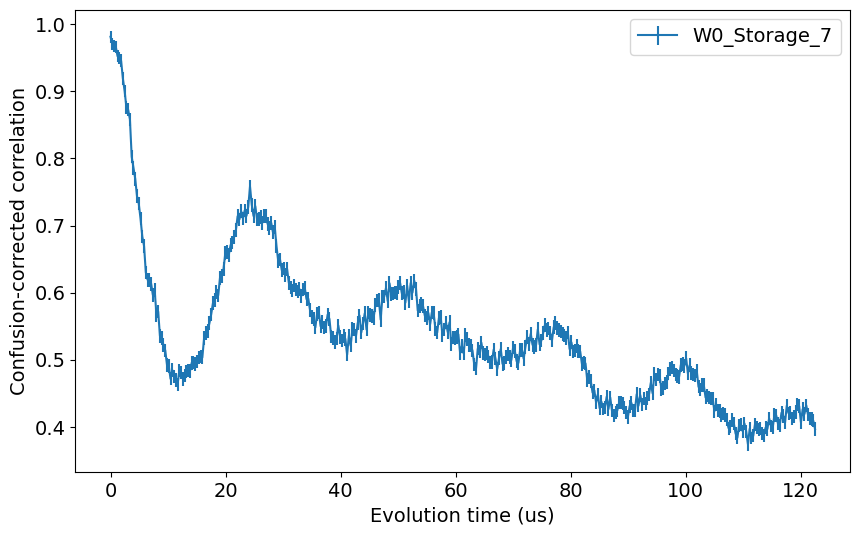

In [43]:
readout_jobs = [load_population_job(filename) for filename in readout_files]
prepared_numbers = [job["config"]["expt"]["occupations"][0] for job in readout_jobs]
calibration = calibrate_readout(readout_jobs, prepared_numbers)
# pilot_jobs = [load_population_job(filename) for filename in pilot_files]
scan_jobs = []
correlations = {}

# population_moments(..., calibration=calibration) applies the same confusion
# correction shown in the walk plot, and propagates shot and calibration errors.
# if pilot_jobs:
#     traces = [population_moments(job, calibration=calibration) for job in pilot_jobs]
#     inputs = [job["config"]["expt"]["occupations"] for job in pilot_jobs]
#     correlations["pilot_Kerr"] = build_correlation(
#         traces, inputs, total_photons=TOTAL_PHOTONS, mode_count=MODE_COUNT,
#         probe="kerr", mode=0,
#     )

for disorder_khz, by_probe in scan_files.items():
    for name, probe, mode in PROBES:
        if name not in by_probe:
            continue
        jobs = [load_population_job(filename) for filename in by_probe[name]]
        scan_jobs.extend(jobs)
        traces = [population_moments(job, calibration=calibration) for job in jobs]
        inputs = [job["config"]["expt"]["occupations"] for job in jobs]
        key = f"W{disorder_khz:g}_{name.replace(' ', '_')}"
        correlations[key] = build_correlation(
            traces, inputs, total_photons=TOTAL_PHOTONS, mode_count=MODE_COUNT,
            probe=probe, mode=mode,
        )

for name, result in correlations.items():
    plt.errorbar(result["time_us"], result["correlation"], yerr=result["standard_error"], label=name)
    print(name, "measured C(0):", result["correlation"][0], "ideal C(0):", result["expected_t0"])
if correlations:
    plt.xlabel("Evolution time (us)")
    plt.ylabel("Confusion-corrected correlation")
    plt.legend()
    plt.show()

In [44]:
# Analysis-only settings; none of these changes measurement or readout.
CUTOFF_KHZ = None  # mean compiled g * MODE_COUNT / DIMENSION
MPM_MAX_MODES = 35
NUMERICAL_GAP_RATIO = None
OUTPUT_DIR = Path("agp_processed")

## 8. Spectral weights, cutoff, and the AGP estimate

Frequencies from Matrix Pencil are cyclic MHz; time is in microseconds.
For angular frequency omega = 2*pi*f and mu = 2*pi*cutoff_mhz, each signed
spectral line contributes `weight * omega**2 / (omega**2 + mu**2)**2`.
Keep both positive and negative frequencies, and remove the zero-frequency
contribution through this filter. Do not divide a cosine's weight twice.
The unnormalized norm has units us^2 for these dimensionless probe operators.

`cutoff = mean(g) * L / D` is an analysis convention, not a coherence rate.
L = 5 and D = 35 here. The default uses the compiled coupling metadata of the
actual pulses. A smaller cutoff emphasizes longer times and unresolved gaps.
Inspect MPM residuals, rank dependence, negative/complex spectral weights,
and variation with fit window before interpreting the inferred norm.

Floquet measurements also require a numerical check that the pulse train
represents the intended static Hamiltonian in the chosen range. The measured
correlation is well-defined even when that approximation fails.

g reference = 20.36 kHz; cutoff = 2.909 kHz


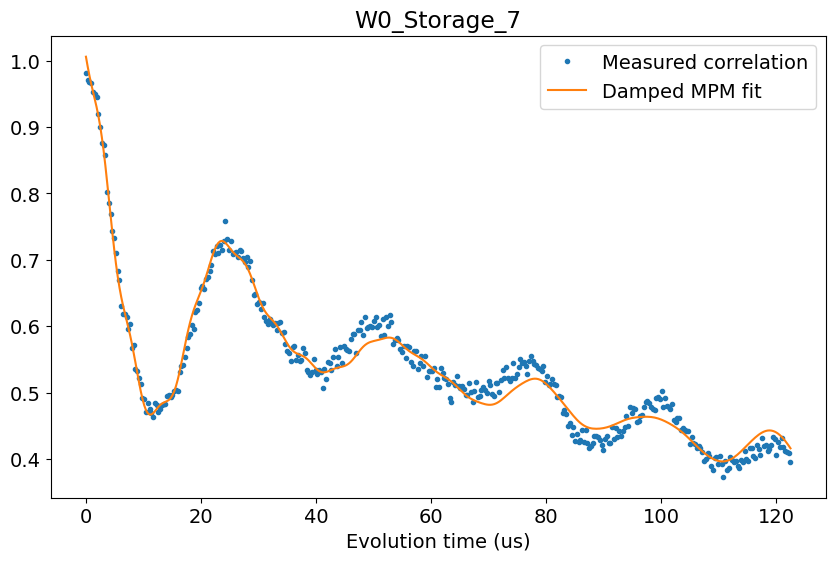

W0_Storage_7 {'values': array([0.42855835]), 'cutoff_mhz': 0.0029090909090909093, 'reference_mhz': 0.020363636363636365, 'units': 'dimensionless; parameter divided by angular reference coupling', 'interpretation': 'zero-decay even-signal inference from fitted poles', 'spectral_filter': array([ 0.64711148,  4.82306271, 10.41370569, 18.40551653, 29.00077244,
       18.40551653, 10.41370569,  4.82306271,  0.64711148])}
MPM diagnostics: {'relative_residual': array([0.06567435]), 'imaginary_fit_fraction': array([0.05792269]), 'negative_real_weight': array([0.0211827]), 'imaginary_weight': array([0.16085556]), 'growing_pole_count': 2, 'maximum_opposite_frequency_distance_mhz': 0.0005783618896137988, 'design_condition_number': 15.760348408775402}


In [45]:
def compiled_reference_mhz(job):
    params = job["metadata"]["derived_params"]
    couplings = np.asarray(params["couplings_MHz"], dtype=float)
    return float(np.mean([couplings[storage - 1] for storage in STORAGE_MODES]))


agp_results = {}
fit_results = {}
if correlations:
    reference_job = ( scan_jobs)[0]
    reference_mhz = compiled_reference_mhz(reference_job)
    cutoff_mhz = 0.001 * CUTOFF_KHZ if CUTOFF_KHZ is not None else reference_mhz * MODE_COUNT / DIMENSION
    print(f"g reference = {1000 * reference_mhz:.4g} kHz; cutoff = {1000 * cutoff_mhz:.4g} kHz")
    for name, result in correlations.items():
        direct = finite_time_agp(result["time_us"], result["correlation"], cutoff_mhz,
                                 covariance=result["covariance"])
        agp_results[name] = dict(finite_time=direct, cutoff_mhz=cutoff_mhz)
        try:
            fit = fit_correlation_mpm(result["time_us"], result["correlation"], max_modes=MPM_MAX_MODES)
        except (ValueError, np.linalg.LinAlgError) as error:
            fit_results[name] = dict(error=str(error))
            print(name, "MPM failed:", error)
            continue
        inferred = regularized_agp_from_fit(fit, cutoff_mhz, reference_mhz=reference_mhz)
        fit_results[name] = fit
        agp_results[name]["inferred"] = inferred
        plt.plot(result["time_us"], result["correlation"], ".", label="Measured correlation")
        plt.plot(result["time_us"], np.real(fit["fitted"][0]), label="Damped MPM fit")
        plt.title(name)
        plt.xlabel("Evolution time (us)")
        plt.legend()
        plt.show()
        print(name, inferred)
        print("MPM diagnostics:", fit["diagnostics"])

## 9. Five disorder curves, their mean, and fit stability

All five curves use the same cutoff and the same angular coupling to make
the norms dimensionless. Their arithmetic mean uses exactly these five probe
operators; it is not an invariant under changing parameter coordinates.
The mean is shown only where all five probes have been acquired.
`NUMERICAL_GAP_RATIO`, if supplied, is a numerical disorder-averaged reference.
It is never extracted from the population measurement.

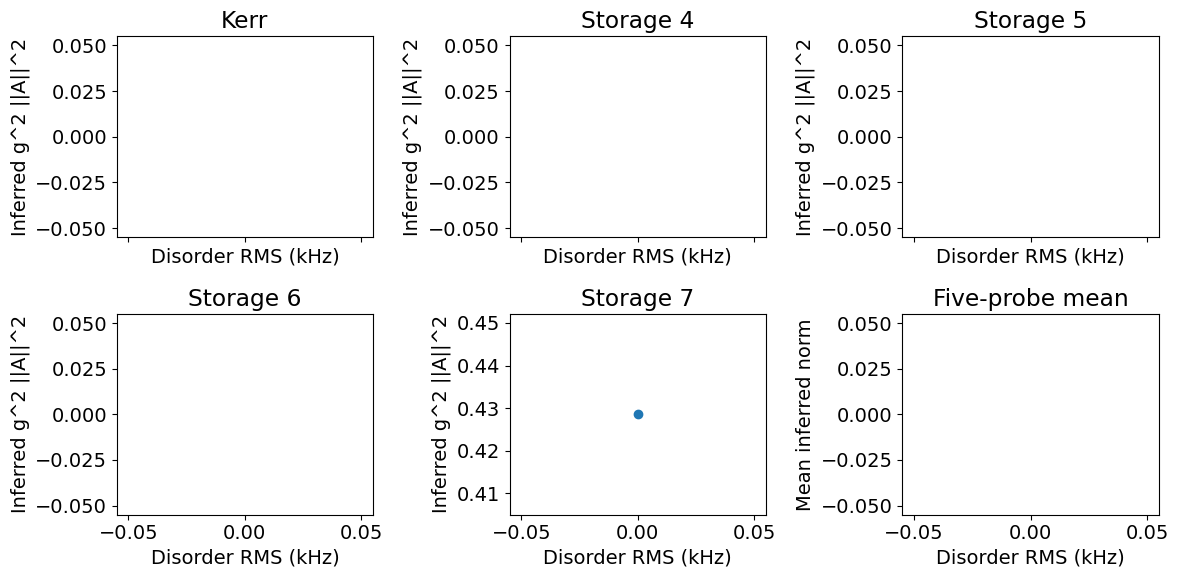

In [46]:
agp_by_disorder = np.full((len(PROBES), len(DISORDER_RMS_KHZ)), np.nan)
for probe_index, (name, probe, mode) in enumerate(PROBES):
    for disorder_index, disorder_khz in enumerate(DISORDER_RMS_KHZ):
        key = f"W{disorder_khz:g}_{name.replace(' ', '_')}"
        if key in agp_results and "inferred" in agp_results[key]:
            agp_by_disorder[probe_index, disorder_index] = agp_results[key]["inferred"]["values"][0]

if np.any(np.isfinite(agp_by_disorder)):
    fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True)
    for index, (name, probe, mode) in enumerate(PROBES):
        axes.flat[index].plot(DISORDER_RMS_KHZ, agp_by_disorder[index], "o-")
        axes.flat[index].set(title=name, xlabel="Disorder RMS (kHz)", ylabel="Inferred g^2 ||A||^2")
    five_mean = np.mean(agp_by_disorder, axis=0)
    axes.flat[5].plot(DISORDER_RMS_KHZ, five_mean, "o-", color="black")
    axes.flat[5].set(title="Five-probe mean", xlabel="Disorder RMS (kHz)", ylabel="Mean inferred norm")
    if NUMERICAL_GAP_RATIO is not None:
        if len(NUMERICAL_GAP_RATIO) != len(DISORDER_RMS_KHZ):
            raise ValueError("Supply one numerical mean gap ratio per disorder strength.")
        reference_axis = axes.flat[5].twinx()
        reference_axis.plot(DISORDER_RMS_KHZ, NUMERICAL_GAP_RATIO, "s--", color="tab:red")
        reference_axis.set_ylabel("Numerical mean gap ratio", color="tab:red")
    fig.tight_layout()
    plt.show()

A small rank/window comparison for one measured correlation. Stable fitted
decay alone does not establish that the inferred weights are the unitary
spectral weights. Compare this spread with shot errors and inspect residuals.
The following spread is a diagnostic, not a confidence interval.

In [20]:
stability_results = {}
if correlations:
    stability_name = "pilot_Kerr" if "pilot_Kerr" in correlations else next(iter(correlations))
    result = correlations[stability_name]
    for modes in [8, 12, 16]:
        for fraction in [0.75, 1.0]:
            points = max(5, int(len(result["time_us"]) * fraction))
            key = f"modes{modes}_window{fraction:g}"
            try:
                fit = fit_correlation_mpm(result["time_us"][:points], result["correlation"][:points], max_modes=modes)
            except (ValueError, np.linalg.LinAlgError) as error:
                stability_results[key] = dict(target=stability_name, error=str(error))
                print(key, "MPM failed:", error)
                continue
            inferred = regularized_agp_from_fit(fit, cutoff_mhz, reference_mhz=reference_mhz)
            stability_results[key] = dict(target=stability_name, estimate=inferred, diagnostics=fit["diagnostics"])
            print(key, inferred["values"], "relative residual:", fit["diagnostics"]["relative_residual"])

modes8_window0.75 [0.14044303] relative residual: [0.02797177]
modes8_window1 [0.14101069] relative residual: [0.02949052]
modes12_window0.75 [0.14846961] relative residual: [0.02936124]
modes12_window1 [0.13999427] relative residual: [0.02426579]
modes16_window0.75 [0.14724763] relative residual: [0.02921307]
modes16_window1 [0.1388386] relative residual: [0.0260474]


## 10. Save processed results separately from raw data

The output contains calibration, correlations and their errors, fit parameters,
cutoff conventions, the fixed disorder pattern, and raw source filenames.
It preserves the observed finite-time estimate separately from the inferred
zero-decay MPM value. The raw HDF5 files remain the canonical shot records.

In [ ]:
if readout_jobs or correlations:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    output_path = OUTPUT_DIR / f"agp_{datetime.now():%Y%m%d_%H%M%S_%f}.h5"
    processed = dict(
        calibration=calibration, correlations=correlations,
        mpm_fits=fit_results, agp=agp_results, stability=stability_results,
        agp_by_disorder=agp_by_disorder, disorder_rms_khz=DISORDER_RMS_KHZ,
        numerical_gap_ratio=NUMERICAL_GAP_RATIO,
        storage_modes=STORAGE_MODES,
        total_photons=TOTAL_PHOTONS, disorder_pattern=DISORDER_PATTERN,
        source_files=[job["source"] for job in readout_jobs + pilot_jobs + scan_jobs],
    )
    save_analysis_h5(output_path, processed, sources=processed["source_files"],
                     metadata=dict(probe_order=[name for name, probe, mode in PROBES]))
    print("Processed data:", output_path)
    reloaded = load_analysis_h5(output_path)

## Next comparison

At fixed Kerr, plot the five inferred AGP norms against disorder strength and
their predefined mean in the same operator convention. A K-versus-W map is a
numerical reference until measurements at other calibrated Kerr points exist.
Compare a fixed experimental disorder pattern with its own numerical model
as well as the disorder-averaged gap-ratio reference; keep those references
distinct. Correlation with level statistics is a question for the data.